In [ ]:
# Metrics Insight
## Zalvantic Internship Programme
### Week 1: Create Metrics You Control

Intern: Muhammad Ismail Shah
Domain: Data Science

Objective:
To generate synthetic application metrics with seasonality,
trend, noise and labelled incidents.

In [2]:
import sys

print("Python Version:", sys.version)

Python Version: 3.13.0 (tags/v3.13.0:60403a5, Oct  7 2024, 09:38:07) [MSC v.1941 64 bit (AMD64)]


In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [6]:
timestamps = pd.date_range(
    start="2026-01-01",
    periods=60 * 24,
    freq="h"
)

In [7]:
df = pd.DataFrame({
    "timestamp": timestamps
})

df.head()

,timestamp
0,2026-01-01 00:00:00
1,2026-01-01 01:00:00
2,2026-01-01 02:00:00
3,2026-01-01 03:00:00
4,2026-01-01 04:00:00


In [8]:
np.random.normal(0, 5, 10)

array([ 0.60866832,  2.85641877,  9.86523956, -3.03768896, -5.2360626 ,
        3.60536284, -7.99983097,  9.02838508,  6.7306752 ,  4.52223355])

In [9]:
# Generate CPU usage data

import numpy as np

# Set random seed for reproducibility
np.random.seed(42)

# Generate 1440 random CPU readings
cpu_usage = 40 + np.random.normal(0, 5, 1440)

# Keep CPU values between 0 and 100
cpu_usage = np.clip(cpu_usage, 0, 100)

# Display first 10 readings
print(cpu_usage[:10])

[42.48357077 39.30867849 43.23844269 47.61514928 38.82923313 38.82931522
 47.89606408 43.83717365 37.65262807 42.71280022]


In [10]:
# Add CPU usage to our existing DataFrame

df["cpu"] = cpu_usage

# Display first 10 rows
df.head(10)

,timestamp,cpu
0,2026-01-01 00:00:00,42.483571
1,2026-01-01 01:00:00,39.308678
2,2026-01-01 02:00:00,43.238443
3,2026-01-01 03:00:00,47.615149
4,2026-01-01 04:00:00,38.829233
5,2026-01-01 05:00:00,38.829315
6,2026-01-01 06:00:00,47.896064
7,2026-01-01 07:00:00,43.837174
8,2026-01-01 08:00:00,37.652628
9,2026-01-01 09:00:00,42.712800


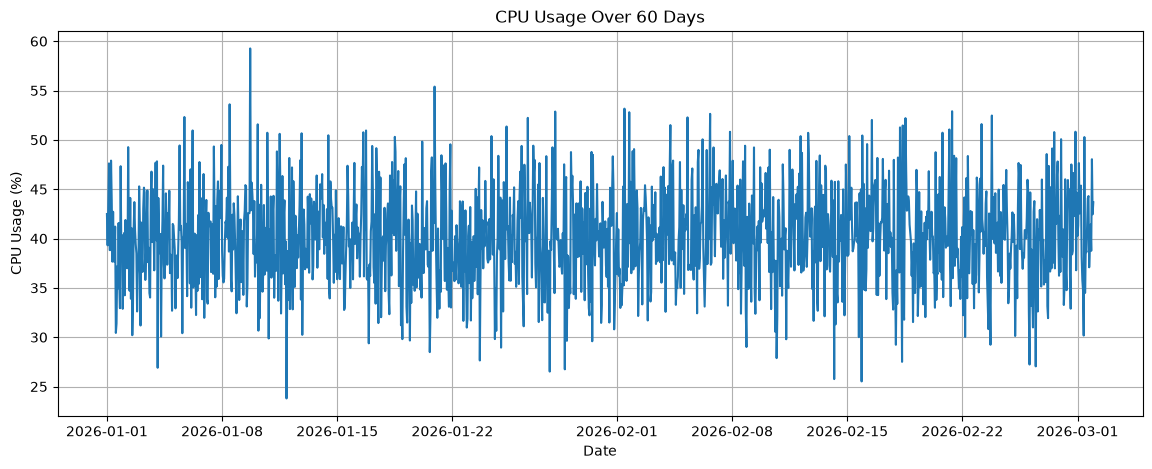

In [12]:
##Visualise CPU usage
plt.figure(figsize=(14, 5))

plt.plot(df["timestamp"], df["cpu"])

plt.title("CPU Usage Over 60 Days")
plt.xlabel("Date")
plt.ylabel("CPU Usage (%)")

plt.grid(True)
plt.show()

In [13]:
##Create daily seasonality
hours = np.arange(1440)

daily_seasonality = 10 * np.sin(2 * np.pi * hours / 24)

print(daily_seasonality[:10])

[ 0.          2.58819045  5.          7.07106781  8.66025404  9.65925826
 10.          9.65925826  8.66025404  7.07106781]


In [14]:
##Create weekly seasonality
weekly_seasonality = 5 * np.sin(2 * np.pi * hours / (24 * 7))

print(weekly_seasonality[:10])

[0.         0.18695597 0.37365047 0.55982238 0.74521133 0.92955804
 1.11260467 1.29409523 1.47377587 1.65139531]


In [15]:
##Add both patterns to CPU usage
cpu_usage = (
    40
    + daily_seasonality
    + weekly_seasonality
    + np.random.normal(0, 3, 1440)
)

cpu_usage = np.clip(cpu_usage, 0, 100)

df["cpu"] = cpu_usage

df.head()

,timestamp,cpu
0,2026-01-01 00:00:00,41.988644
1,2026-01-01 01:00:00,46.295568
2,2026-01-01 02:00:00,45.916715
3,2026-01-01 03:00:00,43.740394
4,2026-01-01 04:00:00,50.604529


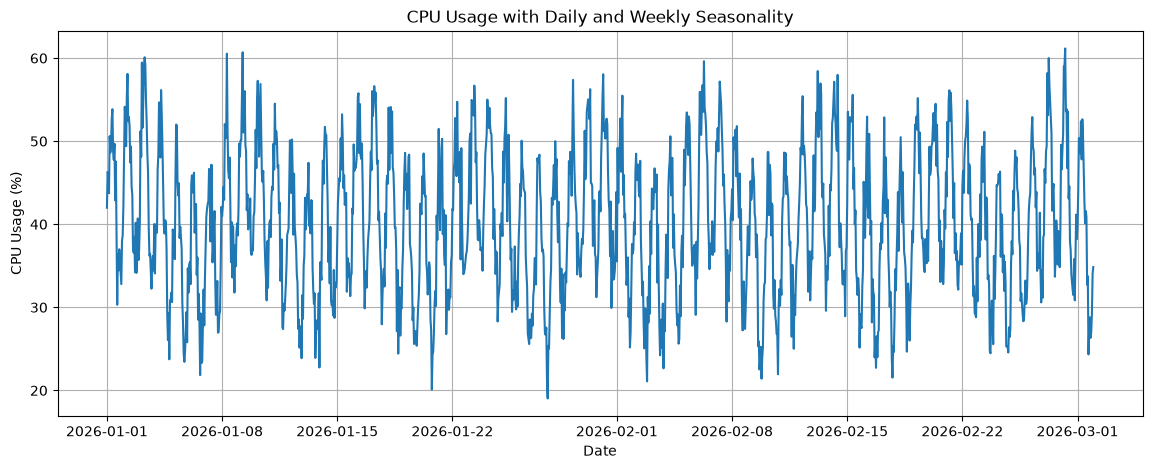

In [16]:
##Visualize the result
plt.figure(figsize=(14, 5))

plt.plot(df["timestamp"], df["cpu"])

plt.title("CPU Usage with Daily and Weekly Seasonality")
plt.xlabel("Date")
plt.ylabel("CPU Usage (%)")

plt.grid(True)
plt.show()

In [17]:
##Generate a trend
trend = np.linspace(0, 15, 1440)

print(trend[:10])
print("Starting trend:", trend[0])
print("Ending trend:", trend[-1])

[0.         0.01042391 0.02084781 0.03127172 0.04169562 0.05211953
 0.06254343 0.07296734 0.08339124 0.09381515]
Starting trend: 0.0
Ending trend: 15.0


In [18]:
##Add trend to CPU usage
cpu_usage = (
    40
    + daily_seasonality
    + weekly_seasonality
    + trend
    + np.random.normal(0, 3, 1440)
)

cpu_usage = np.clip(cpu_usage, 0, 100)

df["cpu"] = cpu_usage

df.head()

,timestamp,cpu
0,2026-01-01 00:00:00,33.285306
1,2026-01-01 01:00:00,36.423470
2,2026-01-01 02:00:00,43.573903
3,2026-01-01 03:00:00,49.035222
4,2026-01-01 04:00:00,41.204646


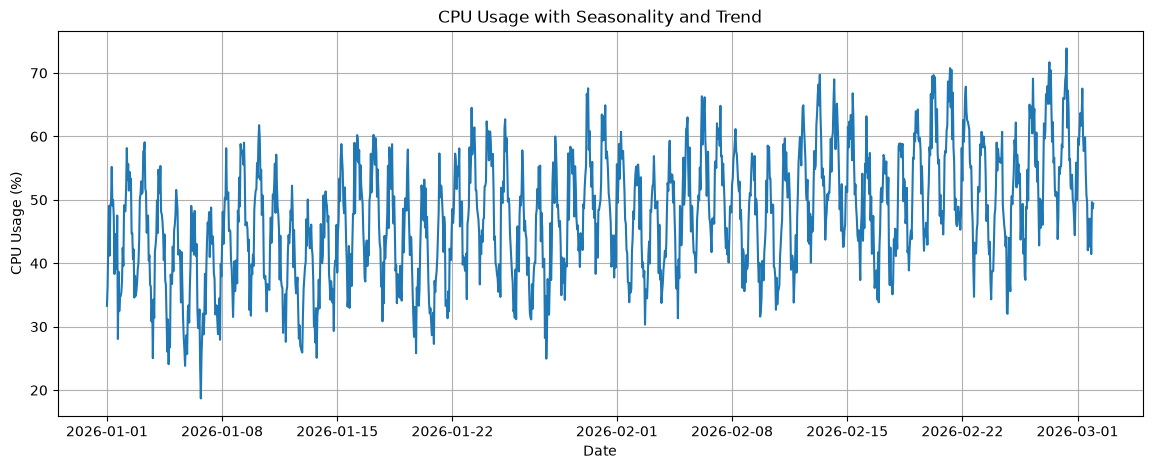

In [19]:
##Visualize the CPU trend
plt.figure(figsize=(14, 5))

plt.plot(df["timestamp"], df["cpu"])

plt.title("CPU Usage with Seasonality and Trend")
plt.xlabel("Date")
plt.ylabel("CPU Usage (%)")

plt.grid(True)
plt.show()

In [20]:
###Generate response time data
response_time = (
    200
    + daily_seasonality * 5
    + weekly_seasonality * 3
    + np.linspace(0, 40, 1440)
    + np.random.normal(0, 15, 1440)
)

response_time = np.clip(response_time, 10, None)

df["response_time"] = response_time

df.head()

,timestamp,cpu,response_time
0,2026-01-01 00:00:00,33.285306,199.701895
1,2026-01-01 01:00:00,36.423470,211.920646
2,2026-01-01 02:00:00,43.573903,244.480789
3,2026-01-01 03:00:00,49.035222,220.968011
4,2026-01-01 04:00:00,41.204646,234.210304


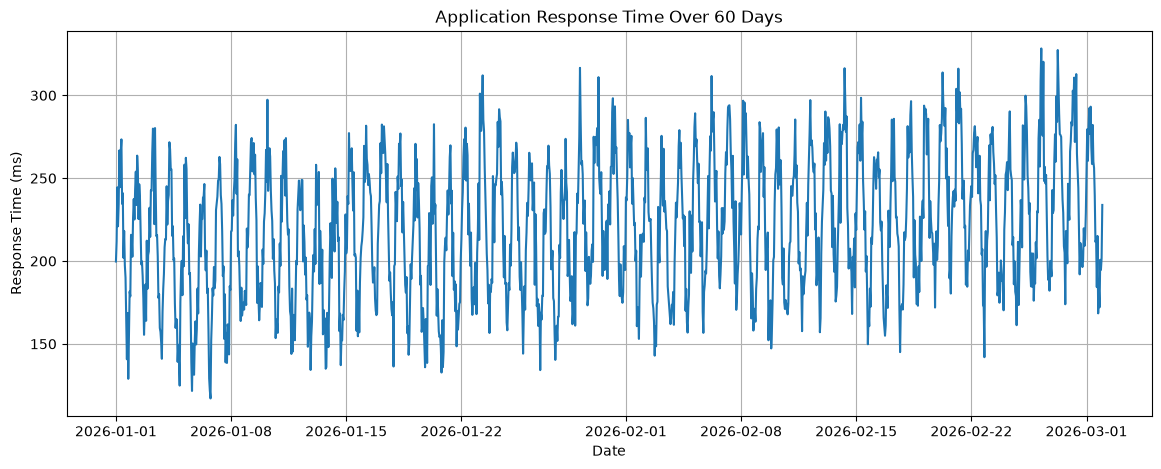

In [21]:
##Visualize response time
plt.figure(figsize=(14, 5))

plt.plot(df["timestamp"], df["response_time"])

plt.title("Application Response Time Over 60 Days")
plt.xlabel("Date")
plt.ylabel("Response Time (ms)")

plt.grid(True)
plt.show()

In [22]:
##Generate error rate data
error_rate = (
    2
    + daily_seasonality * 0.08
    + weekly_seasonality * 0.05
    + np.linspace(0, 1, 1440)
    + np.random.normal(0, 0.3, 1440)
)

error_rate = np.clip(error_rate, 0, 100)

df["error_rate"] = error_rate

df.head()

,timestamp,cpu,response_time,error_rate
0,2026-01-01 00:00:00,33.285306,199.701895,2.008829
1,2026-01-01 01:00:00,36.423470,211.920646,2.372091
2,2026-01-01 02:00:00,43.573903,244.480789,2.125675
3,2026-01-01 03:00:00,49.035222,220.968011,2.174316
4,2026-01-01 04:00:00,41.204646,234.210304,2.765023


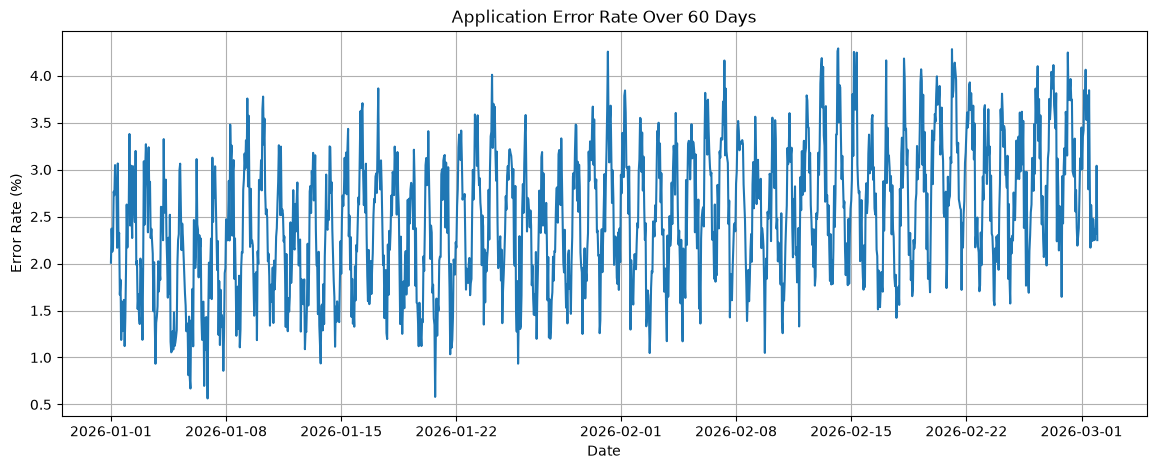

In [23]:
##Visualize error rate
plt.figure(figsize=(14, 5))

plt.plot(df["timestamp"], df["error_rate"])

plt.title("Application Error Rate Over 60 Days")
plt.xlabel("Date")
plt.ylabel("Error Rate (%)")

plt.grid(True)
plt.show()

In [24]:
##Check all three metrics
print("Total rows:", len(df))

print("\nColumns:")
print(df.columns)

print("\nFirst 5 records:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

print("\nStatistical summary:")
display(df[["cpu", "response_time", "error_rate"]].describe())

Total rows: 1440

Columns:
Index(['timestamp', 'cpu', 'response_time', 'error_rate'], dtype='str')

First 5 records:


,timestamp,cpu,response_time,error_rate
0,2026-01-01 00:00:00,33.285306,199.701895,2.008829
1,2026-01-01 01:00:00,36.423470,211.920646,2.372091
2,2026-01-01 02:00:00,43.573903,244.480789,2.125675
3,2026-01-01 03:00:00,49.035222,220.968011,2.174316
4,2026-01-01 04:00:00,41.204646,234.210304,2.765023



Missing values:
timestamp        0
cpu              0
response_time    0
error_rate       0
dtype: int64

Statistical summary:


,cpu,response_time,error_rate
count,1440.000000,1440.000000,1440.000000
mean,47.564221,220.118274,2.498603
std,9.463411,40.819243,0.728190
min,18.689539,117.048780,0.563935
25%,40.500909,186.817201,1.950852
50%,47.761716,219.468426,2.476903
75%,54.748888,251.396779,3.035432
max,73.863443,328.325101,4.289368


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Create 60 days of hourly timestamps
timestamps = pd.date_range(
    start="2026-01-01",
    periods=1440,
    freq="h"
)

# Create DataFrame
df = pd.DataFrame({
    "timestamp": timestamps
})

print("DataFrame created successfully!")

display(df.head())

DataFrame created successfully!


,timestamp
0,2026-01-01 00:00:00
1,2026-01-01 01:00:00
2,2026-01-01 02:00:00
3,2026-01-01 03:00:00
4,2026-01-01 04:00:00


In [7]:
print(type(df))
print("Total rows:", len(df))
print("Total columns:", len(df.columns))

<class 'pandas.DataFrame'>
Total rows: 1440
Total columns: 1


In [9]:
##ADD incedient
df["incident"] = "normal"

display(df.head())

,timestamp,incident
0,2026-01-01 00:00:00,normal
1,2026-01-01 01:00:00,normal
2,2026-01-01 02:00:00,normal
3,2026-01-01 03:00:00,normal
4,2026-01-01 04:00:00,normal


In [10]:
##Add CPU, Response Time and Error Rate
# Generate CPU usage
hours = np.arange(1440)

daily_seasonality = 10 * np.sin(2 * np.pi * hours / 24)
weekly_seasonality = 5 * np.sin(2 * np.pi * hours / 168)
trend = np.linspace(0, 15, 1440)

cpu_usage = (
    40
    + daily_seasonality
    + weekly_seasonality
    + trend
    + np.random.normal(0, 3, 1440)
)

df["cpu"] = np.clip(cpu_usage, 0, 100)


# Generate Response Time
response_time = (
    200
    + daily_seasonality * 5
    + weekly_seasonality * 3
    + np.linspace(0, 40, 1440)
    + np.random.normal(0, 15, 1440)
)

df["response_time"] = np.clip(response_time, 10, None)


# Generate Error Rate
error_rate = (
    2
    + daily_seasonality * 0.08
    + weekly_seasonality * 0.05
    + np.linspace(0, 1, 1440)
    + np.random.normal(0, 0.3, 1440)
)

df["error_rate"] = np.clip(error_rate, 0, 100)

display(df.head())

,timestamp,incident,cpu,response_time,error_rate
0,2026-01-01 00:00:00,normal,41.681609,209.239083,2.209692
1,2026-01-01 01:00:00,normal,40.754609,201.637045,2.230853
2,2026-01-01 02:00:00,normal,49.508019,207.276080,2.183733
3,2026-01-01 03:00:00,normal,45.449765,221.741970,2.717285
4,2026-01-01 04:00:00,normal,48.589792,238.362890,2.682569


In [11]:
##Check all columns
print("Total rows:", len(df))
print("Columns:", df.columns.tolist())

display(df.head())

Total rows: 1440
Columns: ['timestamp', 'incident', 'cpu', 'response_time', 'error_rate']


,timestamp,incident,cpu,response_time,error_rate
0,2026-01-01 00:00:00,normal,41.681609,209.239083,2.209692
1,2026-01-01 01:00:00,normal,40.754609,201.637045,2.230853
2,2026-01-01 02:00:00,normal,49.508019,207.276080,2.183733
3,2026-01-01 03:00:00,normal,45.449765,221.741970,2.717285
4,2026-01-01 04:00:00,normal,48.589792,238.362890,2.682569


In [12]:
##Create incidents
# Spike
df.loc[300:305, "cpu"] += 30
df.loc[300:305, "incident"] = "spike"

# Level Shift
df.loc[600:720, "response_time"] += 100
df.loc[600:720, "incident"] = "level_shift"

# Drift
drift_values = np.linspace(0, 5, 121)
df.loc[900:1020, "error_rate"] += drift_values
df.loc[900:1020, "incident"] = "drift"

# Gap
df.loc[1200:1210, ["cpu", "response_time", "error_rate"]] = np.nan
df.loc[1200:1210, "incident"] = "gap"

print(df["incident"].value_counts())

incident
normal         1181
level_shift     121
drift           121
gap              11
spike             6
Name: count, dtype: int64


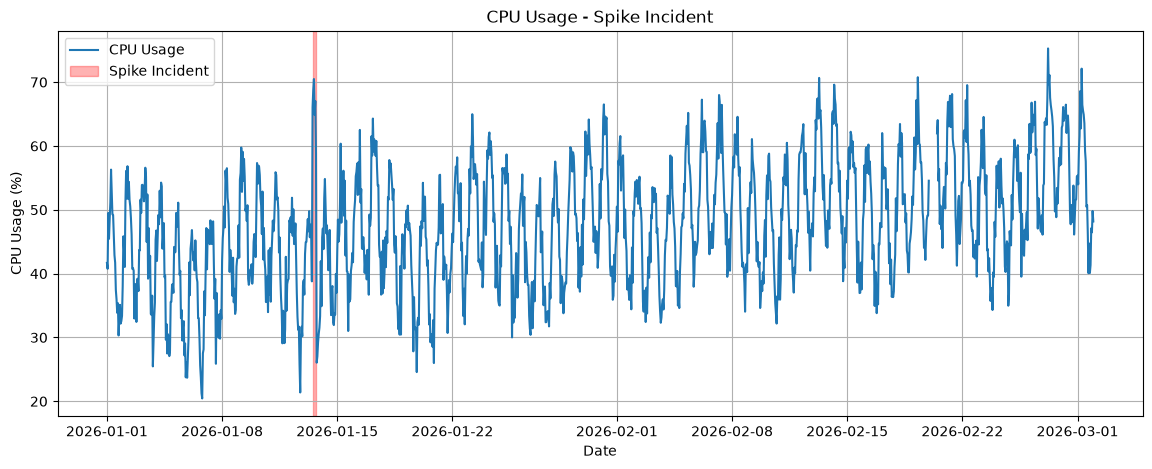

In [13]:
##Visualize Spike
plt.figure(figsize=(14, 5))

plt.plot(df["timestamp"], df["cpu"], label="CPU Usage")

plt.axvspan(
    df["timestamp"].iloc[300],
    df["timestamp"].iloc[305],
    color="red",
    alpha=0.3,
    label="Spike Incident"
)

plt.title("CPU Usage - Spike Incident")
plt.xlabel("Date")
plt.ylabel("CPU Usage (%)")

plt.legend()
plt.grid(True)
plt.show()

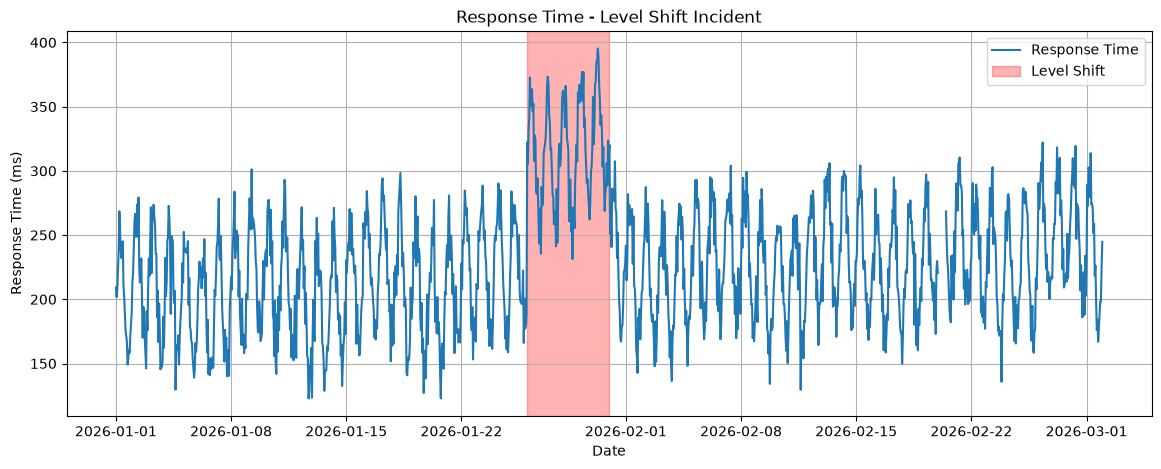

In [14]:
##Visualize Level Shift
plt.figure(figsize=(14, 5))

plt.plot(df["timestamp"], df["response_time"], label="Response Time")

plt.axvspan(
    df["timestamp"].iloc[600],
    df["timestamp"].iloc[720],
    color="red",
    alpha=0.3,
    label="Level Shift"
)

plt.title("Response Time - Level Shift Incident")
plt.xlabel("Date")
plt.ylabel("Response Time (ms)")

plt.legend()
plt.grid(True)
plt.show()

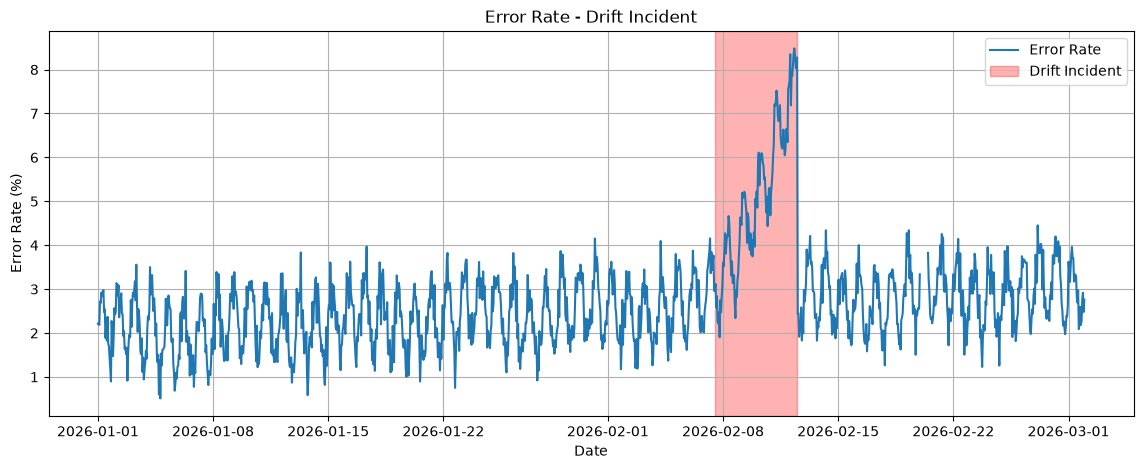

In [15]:
##Visualize Drift
plt.figure(figsize=(14, 5))

plt.plot(df["timestamp"], df["error_rate"], label="Error Rate")

plt.axvspan(
    df["timestamp"].iloc[900],
    df["timestamp"].iloc[1020],
    color="red",
    alpha=0.3,
    label="Drift Incident"
)

plt.title("Error Rate - Drift Incident")
plt.xlabel("Date")
plt.ylabel("Error Rate (%)")

plt.legend()
plt.grid(True)
plt.show()

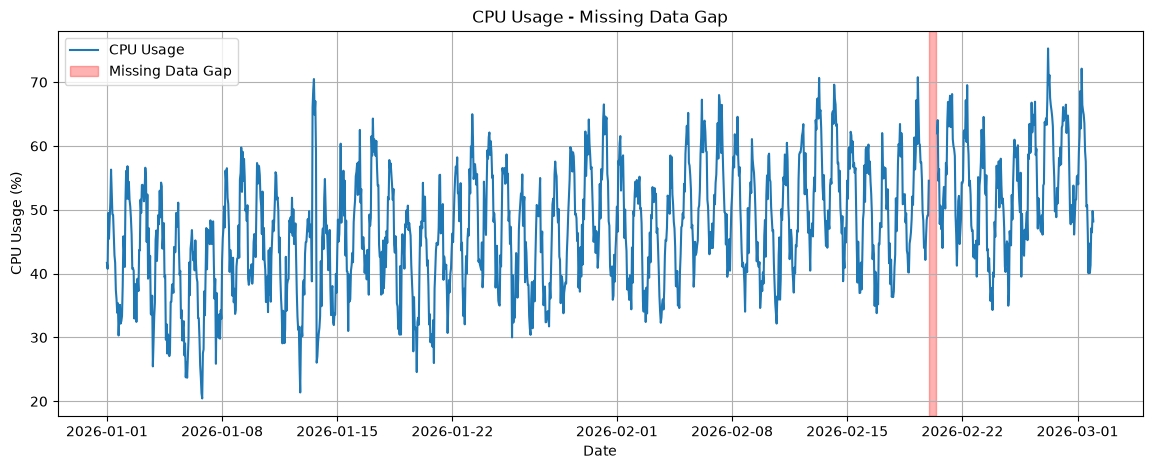

In [16]:
##Visualize Missing Data Gap
plt.figure(figsize=(14, 5))

plt.plot(df["timestamp"], df["cpu"], label="CPU Usage")

plt.axvspan(
    df["timestamp"].iloc[1200],
    df["timestamp"].iloc[1210],
    color="red",
    alpha=0.3,
    label="Missing Data Gap"
)

plt.title("CPU Usage - Missing Data Gap")
plt.xlabel("Date")
plt.ylabel("CPU Usage (%)")

plt.legend()
plt.grid(True)
plt.show()

In [17]:
##Final incident verification
print("Incident Summary")
print("----------------")

print(df["incident"].value_counts())

print("\nMissing Values:")
print(df[["cpu", "response_time", "error_rate"]].isnull().sum())

Incident Summary
----------------
incident
normal         1181
level_shift     121
drift           121
gap              11
spike             6
Name: count, dtype: int64

Missing Values:
cpu              11
response_time    11
error_rate       11
dtype: int64


In [19]:
df.to_csv("metrics_insight_week1.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [20]:
import os

print("Current folder:", os.getcwd())

print("\nFiles in current folder:")
print(os.listdir())

Current folder: C:\Users\PROFESSOR

Files in current folder:
['.android', '.antigravity', '.bash_history', '.cache', '.cursor', '.dnx', '.expo', '.gemini', '.gradle', '.ipynb_checkpoints', '.ipython', '.jbr', '.jupyter', '.packettracer', '.skiko', '.thumbnails', '.TurboVPN', '.vscode', '.vscode-shared', '3D Objects', 'AndroidStudioProjects', 'AppData', 'Application Data', 'Car details v3.csv', 'Car Price Prediction.ipynb', 'Cisco Packet Tracer 8.2.2', 'cleaned_titanic.csv', 'Contacts', 'Cookies', 'Desktop', 'Documents', 'Downloads', 'Endless Runner', 'Endless Runner Game', 'Endless RunnerGame', 'Favorites', 'Google Play Store Analysis.ipynb', 'googleplaystore.csv', 'HCI', 'House Price Prediction.ipynb', 'IMDB_dataset.csv', 'IntelGraphicsProfiles', 'Iris_Flower_Classification.ipynb', 'Links', 'Local Settings', 'Local Sites', 'metrics_insight_week1.csv', 'Microsoft', 'muneeb', 'Music', 'My Documents', 'NetHood', 'NTUSER.DAT', 'ntuser.dat.LOG1', 'ntuser.dat.LOG2', 'NTUSER.DAT{53b39e87-18c

In [22]:
df_check = pd.read_csv("metrics_insight_week1.csv")

print("Dataset loaded successfully!")

print("Total rows:", len(df_check))

display(df_check.head())

Dataset loaded successfully!
Total rows: 1440


,timestamp,incident,cpu,response_time,error_rate
0,2026-01-01 00:00:00,normal,41.681609,209.239083,2.209692
1,2026-01-01 01:00:00,normal,40.754609,201.637045,2.230853
2,2026-01-01 02:00:00,normal,49.508019,207.276080,2.183733
3,2026-01-01 03:00:00,normal,45.449765,221.741970,2.717285
4,2026-01-01 04:00:00,normal,48.589792,238.362890,2.682569


In [24]:
##verfication
print(df_check["incident"].value_counts())

print("\nMissing values:")
print(df_check.isnull().sum())

incident
normal         1181
level_shift     121
drift           121
gap              11
spike             6
Name: count, dtype: int64

Missing values:
timestamp         0
incident          0
cpu              11
response_time    11
error_rate       11
dtype: int64


In [25]:
##Install required libraries
%pip install fastapi uvicorn sqlmodel

   ---------------------------------------- 0.0/2.4 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.4 MB ? eta -:--:--
   -------- ------------------------------- 0.5/2.4 MB 1.5 MB/s eta 0:00:02
   ------------ --------------------------- 0.8/2.4 MB 1.5 MB/s eta 0:00:02
   --------------------- ------------------ 1.3/2.4 MB 1.5 MB/s eta 0:00:01
   ------------------------- -------------- 1.6/2.4 MB 1.6 MB/s eta 0:00:01
   ------------------------------ --------- 1.8/2.4 MB 1.5 MB/s eta 0:00:01
   ---------------------------------- ----- 2.1/2.4 MB 1.5 MB/s eta 0:00:01
   ---------------------------------------- 2.4/2.4 MB 1.4 MB/s  0:00:01
   ---------------------------------------- 0.0/2.3 MB ? eta -:--:--
   ---- ----------------------------------- 0.3/2.3 MB ? eta -:--:--
   --------- ------------------------------ 0.5/2.3 MB 1.3 MB/s eta 0:00:02
   ------------- -------------------------- 0.8/2.3 MB 1.3 MB/s eta 0:00:02
   ------------------ ---------------------


[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [30]:
code = """
from fastapi import FastAPI

app = FastAPI(
    title="Metrics Insight API",
    description="API for application metrics monitoring",
    version="1.0.0"
)

@app.get("/")
def home():
    return {
        "message": "Welcome to Metrics Insight API",
        "status": "Running"
    }

@app.get("/health")
def health():
    return {
        "status": "Healthy"
    }
"""

with open("main.py", "w") as file:
    file.write(code)

print("main.py updated successfully!")

main.py updated successfully!


In [32]:
## check file
with open("main.py", "r") as file:
    print(file.read())


from fastapi import FastAPI

app = FastAPI(
    title="Metrics Insight API",
    description="API for application metrics monitoring",
    version="1.0.0"
)

@app.get("/")
def home():
    return {
        "message": "Welcome to Metrics Insight API",
        "status": "Running"
    }

@app.get("/health")
def health():
    return {
        "status": "Healthy"
    }



In [34]:
##Test your API
from fastapi.testclient import TestClient
from main import app

client = TestClient(app)

response = client.get("/")

print("Status Code:", response.status_code)
print("Response:", response.json())

Status Code: 200
Response: {'message': 'Welcome to Metrics Insight API', 'status': 'Running'}


In [35]:
## Health test point
response = client.get("/health")

print(response.status_code)
print(response.json())

200
{'status': 'Healthy'}


In [36]:
##Check SQLModel installation
import sqlmodel

print("SQLModel version:", sqlmodel.__version__)
print("SQLModel imported successfully!")

SQLModel version: 0.0.48
SQLModel imported successfully!


In [37]:
%pip install sqlmodel


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.3 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [38]:
###Create models.py
model_code = """
from datetime import datetime
from sqlmodel import SQLModel, Field


class MetricPoint(SQLModel, table=True):

    id: int | None = Field(default=None, primary_key=True)

    service: str = Field(index=True)

    metric: str = Field(index=True)

    timestamp: datetime = Field(index=True)

    value: float
"""

with open("models.py", "w") as file:
    file.write(model_code)

print("models.py created successfully!")

models.py created successfully!


In [40]:
##Create database.py
database_code = """
from sqlmodel import SQLModel, create_engine

DATABASE_URL = "sqlite:///metrics_insight.db"

engine = create_engine(
    DATABASE_URL,
    echo=True
)

def create_db_and_tables():
    SQLModel.metadata.create_all(engine)
"""

with open("database.py", "w") as file:
    file.write(database_code)

print("database.py created successfully!")

database.py created successfully!


In [41]:
###Create the database table
from sqlmodel import SQLModel, create_engine
from models import MetricPoint

DATABASE_URL = "sqlite:///metrics_insight.db"

engine = create_engine(
    DATABASE_URL,
    echo=True
)

SQLModel.metadata.create_all(engine)

print("Database and tables created successfully!")

2026-11-10 14:50:59,282 INFO sqlalchemy.engine.Engine BEGIN (implicit)
2026-11-10 14:50:59,288 INFO sqlalchemy.engine.Engine PRAGMA main.table_info("metricpoint")
2026-11-10 14:50:59,365 INFO sqlalchemy.engine.Engine [raw sql] ()
2026-11-10 14:50:59,383 INFO sqlalchemy.engine.Engine PRAGMA temp.table_info("metricpoint")
2026-11-10 14:50:59,386 INFO sqlalchemy.engine.Engine [raw sql] ()
2026-11-10 14:50:59,391 INFO sqlalchemy.engine.Engine 
CREATE TABLE metricpoint (
	id INTEGER NOT NULL, 
	service VARCHAR NOT NULL, 
	metric VARCHAR NOT NULL, 
	timestamp DATETIME NOT NULL, 
	value FLOAT NOT NULL, 
	PRIMARY KEY (id)
)


2026-11-10 14:50:59,395 INFO sqlalchemy.engine.Engine [no key 0.00385s] ()
2026-11-10 14:50:59,421 INFO sqlalchemy.engine.Engine CREATE INDEX ix_metricpoint_metric ON metricpoint (metric)
2026-11-10 14:50:59,431 INFO sqlalchemy.engine.Engine [no key 0.00983s] ()
2026-11-10 14:50:59,469 INFO sqlalchemy.engine.Engine CREATE INDEX ix_metricpoint_timestamp ON metricpoint (tim

In [42]:
##Verify the database
import os

print("Database file exists:", os.path.exists("metrics_insight.db"))

print("Project files:")

for file in os.listdir():
    if file.endswith(".py") or file.endswith(".db"):
        print(file)

Database file exists: True
Project files:
database.py
main.py
metrics_insight.db
models.py


In [44]:
from sqlmodel import Session
from datetime import datetime, timezone
from models import MetricPoint

with Session(engine) as session:

    new_metric = MetricPoint(
        service="website",
        metric="cpu",
        timestamp=datetime(2026, 1, 1, 10, 0, tzinfo=timezone.utc),
        value=45.5
    )

    session.add(new_metric)
    session.commit()
    session.refresh(new_metric)

    print("Record saved successfully!")
    print(new_metric)

2026-11-10 14:54:12,582 INFO sqlalchemy.engine.Engine BEGIN (implicit)
2026-11-10 14:54:12,585 INFO sqlalchemy.engine.Engine INSERT INTO metricpoint (service, metric, timestamp, value) VALUES (?, ?, ?, ?)
2026-11-10 14:54:12,589 INFO sqlalchemy.engine.Engine [cached since 118.1s ago] ('website', 'cpu', '2026-01-01 10:00:00.000000', 45.5)
2026-11-10 14:54:12,593 INFO sqlalchemy.engine.Engine COMMIT
2026-11-10 14:54:12,608 INFO sqlalchemy.engine.Engine BEGIN (implicit)
2026-11-10 14:54:12,615 INFO sqlalchemy.engine.Engine SELECT metricpoint.id, metricpoint.service, metricpoint.metric, metricpoint.timestamp, metricpoint.value 
FROM metricpoint 
WHERE metricpoint.id = ?
2026-11-10 14:54:12,616 INFO sqlalchemy.engine.Engine [generated in 0.00118s] (1,)
Record saved successfully!
value=45.5 id=1 metric='cpu' timestamp=datetime.datetime(2026, 1, 1, 10, 0, tzinfo=datetime.timezone.utc) service='website'
2026-11-10 14:54:12,621 INFO sqlalchemy.engine.Engine ROLLBACK


In [45]:
from datetime import datetime, timezone

In [46]:
tzinfo=timezone.utc

In [47]:
##verify the record
from sqlmodel import Session, select
from models import MetricPoint

with Session(engine) as session:

    statement = select(MetricPoint)
    results = session.exec(statement).all()

    for record in results:
        print(record)

2026-11-10 14:56:18,528 INFO sqlalchemy.engine.Engine BEGIN (implicit)
2026-11-10 14:56:18,532 INFO sqlalchemy.engine.Engine SELECT metricpoint.id, metricpoint.service, metricpoint.metric, metricpoint.timestamp, metricpoint.value 
FROM metricpoint
2026-11-10 14:56:18,534 INFO sqlalchemy.engine.Engine [generated in 0.00269s] ()
value=45.5 id=1 metric='cpu' timestamp=datetime.datetime(2026, 1, 1, 10, 0, tzinfo=datetime.timezone.utc) service='website'
2026-11-10 14:56:18,537 INFO sqlalchemy.engine.Engine ROLLBACK


In [49]:
##  Read the record
from sqlmodel import Session, select
from models import MetricPoint

with Session(engine) as session:
    statement = select(MetricPoint)
    results = session.exec(statement).all()

    for record in results:
        print(record)

2026-11-10 15:02:46,537 INFO sqlalchemy.engine.Engine BEGIN (implicit)
2026-11-10 15:02:46,538 INFO sqlalchemy.engine.Engine SELECT metricpoint.id, metricpoint.service, metricpoint.metric, metricpoint.timestamp, metricpoint.value 
FROM metricpoint
2026-11-10 15:02:46,539 INFO sqlalchemy.engine.Engine [cached since 388s ago] ()
value=45.5 id=1 metric='cpu' timestamp=datetime.datetime(2026, 1, 1, 10, 0, tzinfo=datetime.timezone.utc) service='website'
2026-11-10 15:02:46,542 INFO sqlalchemy.engine.Engine ROLLBACK


In [50]:
##CSV file read karna
import pandas as pd

df = pd.read_csv("metrics_insight_week1.csv")

print("Dataset loaded successfully!")
print(df.head())

Dataset loaded successfully!
             timestamp incident        cpu  response_time  error_rate
0  2026-01-01 00:00:00   normal  41.681609     209.239083    2.209692
1  2026-01-01 01:00:00   normal  40.754609     201.637045    2.230853
2  2026-01-01 02:00:00   normal  49.508019     207.276080    2.183733
3  2026-01-01 03:00:00   normal  45.449765     221.741970    2.717285
4  2026-01-01 04:00:00   normal  48.589792     238.362890    2.682569


In [51]:
##Dataset check karna
print("Total rows:", len(df))

print("\nDataset columns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

Total rows: 1440

Dataset columns:
['timestamp', 'incident', 'cpu', 'response_time', 'error_rate']

Missing values:
timestamp         0
incident          0
cpu              11
response_time    11
error_rate       11
dtype: int64


In [52]:
from datetime import timezone
import pandas as pd

df["timestamp"] = pd.to_datetime(df["timestamp"], utc=True)

metric_columns = ["cpu", "response_time", "error_rate"]

records = []

for _, row in df.iterrows():

    for metric_name in metric_columns:

        value = row[metric_name]

        if pd.notna(value):

            record = {
                "service": "metrics-insight",
                "metric": metric_name,
                "timestamp": row["timestamp"].to_pydatetime(),
                "value": float(value)
            }

            records.append(record)

print("Total records ready:", len(records))
print(records[:3])

Total records ready: 4287
[{'service': 'metrics-insight', 'metric': 'cpu', 'timestamp': datetime.datetime(2026, 1, 1, 0, 0, tzinfo=datetime.timezone.utc), 'value': 41.681608979518096}, {'service': 'metrics-insight', 'metric': 'response_time', 'timestamp': datetime.datetime(2026, 1, 1, 0, 0, tzinfo=datetime.timezone.utc), 'value': 209.23908307666213}, {'service': 'metrics-insight', 'metric': 'error_rate', 'timestamp': datetime.datetime(2026, 1, 1, 0, 0, tzinfo=datetime.timezone.utc), 'value': 2.209691976898598}]


In [ ]:
##insert the database record
from sqlmodel import Session
from models import MetricPoint

with Session(engine) as session:

    metric_objects = [
        MetricPoint(**record)
        for record in records
    ]

    session.add_all(metric_objects)

    session.commit()

    print("All records inserted successfully!")
    print("Total inserted records:", len(metric_objects))

2026-11-10 15:08:02,786 INFO sqlalchemy.engine.Engine BEGIN (implicit)
2026-11-10 15:08:02,852 INFO sqlalchemy.engine.Engine INSERT INTO metricpoint (service, metric, timestamp, value) VALUES (?, ?, ?, ?) RETURNING id
2026-11-10 15:08:02,853 INFO sqlalchemy.engine.Engine [generated in 0.02050s (insertmanyvalues) 1/4287 (ordered; batch not supported)] ('metrics-insight', 'cpu', '2026-01-01 00:00:00.000000', 41.681608979518096)
2026-11-10 15:08:02,855 INFO sqlalchemy.engine.Engine INSERT INTO metricpoint (service, metric, timestamp, value) VALUES (?, ?, ?, ?) RETURNING id
2026-11-10 15:08:02,856 INFO sqlalchemy.engine.Engine [insertmanyvalues 2/4287 (ordered; batch not supported)] ('metrics-insight', 'response_time', '2026-01-01 00:00:00.000000', 209.23908307666213)
2026-11-10 15:08:02,858 INFO sqlalchemy.engine.Engine INSERT INTO metricpoint (service, metric, timestamp, value) VALUES (?, ?, ?, ?) RETURNING id
2026-11-10 15:08:02,858 INFO sqlalchemy.engine.Engine [insertmanyvalues 3/4287

IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)



2026-11-10 15:08:10,430 INFO sqlalchemy.engine.Engine [insertmanyvalues 3575/4287 (ordered; batch not supported)] ('metrics-insight', 'response_time', '2026-02-19 15:00:00.000000', 207.20264037203847)
2026-11-10 15:08:10,431 INFO sqlalchemy.engine.Engine INSERT INTO metricpoint (service, metric, timestamp, value) VALUES (?, ?, ?, ?) RETURNING id
2026-11-10 15:08:10,432 INFO sqlalchemy.engine.Engine [insertmanyvalues 3576/4287 (ordered; batch not supported)] ('metrics-insight', 'error_rate', '2026-02-19 15:00:00.000000', 2.5362101877811627)
2026-11-10 15:08:10,433 INFO sqlalchemy.engine.Engine INSERT INTO metricpoint (service, metric, timestamp, value) VALUES (?, ?, ?, ?) RETURNING id
2026-11-10 15:08:10,434 INFO sqlalchemy.engine.Engine [insertmanyvalues 3577/4287 (ordered; batch not supported)] ('metrics-insight', 'cpu', '2026-02-19 16:00:00.000000', 44.05312791986077)
2026-11-10 15:08:10,437 INFO sqlalchemy.engine.Engine INSERT INTO metricpoint (service, metric, timestamp, value) VAL

In [54]:
## verify the database record
from sqlmodel import Session, select
from models import MetricPoint

with Session(engine) as session:

    statement = select(MetricPoint)
    all_records = session.exec(statement).all()

    print("Total database records:", len(all_records))

2026-11-10 15:14:44,224 INFO sqlalchemy.engine.Engine BEGIN (implicit)
2026-11-10 15:14:44,225 INFO sqlalchemy.engine.Engine SELECT metricpoint.id, metricpoint.service, metricpoint.metric, metricpoint.timestamp, metricpoint.value 
FROM metricpoint
2026-11-10 15:14:44,227 INFO sqlalchemy.engine.Engine [cached since 1106s ago] ()
Total database records: 4288
2026-11-10 15:14:44,389 INFO sqlalchemy.engine.Engine ROLLBACK


In [55]:
# counteach one
from sqlmodel import Session, select
from models import MetricPoint

with Session(engine) as session:

    for metric_name in ["cpu", "response_time", "error_rate"]:

        statement = select(MetricPoint).where(
            MetricPoint.metric == metric_name
        )

        results = session.exec(statement).all()

        print(metric_name, "records:", len(results))

2026-11-10 15:16:09,057 INFO sqlalchemy.engine.Engine BEGIN (implicit)
2026-11-10 15:16:09,060 INFO sqlalchemy.engine.Engine SELECT metricpoint.id, metricpoint.service, metricpoint.metric, metricpoint.timestamp, metricpoint.value 
FROM metricpoint 
WHERE metricpoint.metric = ?
2026-11-10 15:16:09,062 INFO sqlalchemy.engine.Engine [generated in 0.00170s] ('cpu',)
cpu records: 1430
2026-11-10 15:16:09,103 INFO sqlalchemy.engine.Engine SELECT metricpoint.id, metricpoint.service, metricpoint.metric, metricpoint.timestamp, metricpoint.value 
FROM metricpoint 
WHERE metricpoint.metric = ?
2026-11-10 15:16:09,104 INFO sqlalchemy.engine.Engine [cached since 0.04431s ago] ('response_time',)
response_time records: 1429
2026-11-10 15:16:09,146 INFO sqlalchemy.engine.Engine SELECT metricpoint.id, metricpoint.service, metricpoint.metric, metricpoint.timestamp, metricpoint.value 
FROM metricpoint 
WHERE metricpoint.metric = ?
2026-11-10 15:16:09,146 INFO sqlalchemy.engine.Engine [cached since 0.0865

In [56]:
##check save record
with Session(engine) as session:

    statement = select(MetricPoint).limit(10)

    results = session.exec(statement).all()

    for record in results:
        print(
            record.id,
            record.service,
            record.metric,
            record.timestamp,
            record.value
        )

2026-11-10 15:27:03,521 INFO sqlalchemy.engine.Engine BEGIN (implicit)
2026-11-10 15:27:03,524 INFO sqlalchemy.engine.Engine SELECT metricpoint.id, metricpoint.service, metricpoint.metric, metricpoint.timestamp, metricpoint.value 
FROM metricpoint
 LIMIT ? OFFSET ?
2026-11-10 15:27:03,527 INFO sqlalchemy.engine.Engine [generated in 0.00273s] (10, 0)
1 website cpu 2026-01-01 10:00:00+00:00 45.5
2 metrics-insight cpu 2026-01-01 00:00:00+00:00 41.681608979518096
3 metrics-insight response_time 2026-01-01 00:00:00+00:00 209.23908307666213
4 metrics-insight error_rate 2026-01-01 00:00:00+00:00 2.209691976898598
5 metrics-insight cpu 2026-01-01 01:00:00+00:00 40.75460947634962
6 metrics-insight response_time 2026-01-01 01:00:00+00:00 201.63704505042887
7 metrics-insight error_rate 2026-01-01 01:00:00+00:00 2.2308525897437472
8 metrics-insight cpu 2026-01-01 02:00:00+00:00 49.50801862836614
9 metrics-insight response_time 2026-01-01 02:00:00+00:00 207.2760798022918
10 metrics-insight error_ra

In [12]:
##update main.py

code = """
from fastapi import FastAPI, Depends
from sqlmodel import Session, select
from datetime import datetime, timezone

from database import engine
from models import MetricPoint

app = FastAPI(
    title="Metrics Insight API",
    description="API for application metrics monitoring",
    version="1.0.0"
)


def get_session():
    with Session(engine) as session:
        yield session


@app.get("/")
def home():
    return {
        "message": "Welcome to Metrics Insight API",
        "status": "Running"
    }


@app.get("/health")
def health():
    return {"status": "Healthy"}


@app.post("/metrics")
def create_metric(metric: MetricPoint, session: Session = Depends(get_session)):

    timestamp = datetime.fromisoformat(
        str(metric.timestamp).replace("Z", "+00:00")
    )

    if timestamp.tzinfo is None:
        timestamp = timestamp.replace(tzinfo=timezone.utc)

    metric.timestamp = timestamp
    metric.id = None

    session.add(metric)
    session.commit()
    session.refresh(metric)

    return {
        "message": "Metric saved successfully",
        "data": metric
    }


@app.get("/metrics")
def get_metrics(session: Session = Depends(get_session)):

    statement = select(MetricPoint)
    results = session.exec(statement).all()

    return {
        "total_records": len(results),
        "data": results
    }
"""

with open("main.py", "w") as file:
    file.write(code)
print("main.py updated successfully!")

main.py updated successfully!


In [13]:
import importlib
import main

importlib.reload(main)

from fastapi.testclient import TestClient

client = TestClient(main.app)

response = client.get("/metrics")

print("Status code:", response.status_code)
print("Total records:", response.json()["total_records"])

2026-11-12 20:08:24,014 INFO sqlalchemy.engine.Engine BEGIN (implicit)
2026-11-12 20:08:24,025 INFO sqlalchemy.engine.Engine SELECT metricpoint.id, metricpoint.service, metricpoint.metric, metricpoint.timestamp, metricpoint.value 
FROM metricpoint
2026-11-12 20:08:24,027 INFO sqlalchemy.engine.Engine [generated in 0.00204s] ()


C:\Users\PROFESSOR\AppData\Local\Programs\Python\Python313\Lib\site-packages\fastapi\testclient.py:1: StarletteDeprecationWarning: Using `httpx` with `starlette.testclient` is deprecated; install `httpx2` instead.
  from starlette.testclient import TestClient as TestClient  # noqa


2026-11-12 20:08:24,555 INFO sqlalchemy.engine.Engine ROLLBACK
Status code: 200
Total records: 4291


In [14]:
response = client.get("/metrics")

print("Status code:", response.status_code)
print("Total records:", response.json()["total_records"])

2026-11-12 20:11:15,304 INFO sqlalchemy.engine.Engine BEGIN (implicit)
2026-11-12 20:11:15,312 INFO sqlalchemy.engine.Engine SELECT metricpoint.id, metricpoint.service, metricpoint.metric, metricpoint.timestamp, metricpoint.value 
FROM metricpoint
2026-11-12 20:11:15,316 INFO sqlalchemy.engine.Engine [cached since 171.3s ago] ()
2026-11-12 20:11:15,776 INFO sqlalchemy.engine.Engine ROLLBACK
Status code: 200
Total records: 4291


In [16]:
!git --version

git version 2.52.0.windows.1


In [17]:
import os

print("Current folder:", os.getcwd())

print("\nProject files:")
for file in os.listdir():
    print(file)

Current folder: C:\Users\PROFESSOR

Project files:
.android
.antigravity
.bash_history
.cache
.cursor
.dnx
.expo
.gemini
.gradle
.ipynb_checkpoints
.ipython
.jbr
.jupyter
.packettracer
.skiko
.thumbnails
.TurboVPN
.vscode
.vscode-shared
3D Objects
AndroidStudioProjects
AppData
Application Data
Car details v3.csv
Car Price Prediction.ipynb
Cisco Packet Tracer 8.2.2
cleaned_titanic.csv
Contacts
Cookies
database.py
Desktop
Documents
Downloads
Endless Runner
Endless Runner Game
Endless RunnerGame
Favorites
Google Play Store Analysis.ipynb
googleplaystore.csv
HCI
House Price Prediction.ipynb
IMDB_dataset.csv
IntelGraphicsProfiles
Iris_Flower_Classification.ipynb
Links
Local Settings
Local Sites
main.py
metrics_insight.db
metrics_insight_week1.csv
Microsoft
models.py
muneeb
Music
My Documents
NetHood
NTUSER.DAT
ntuser.dat.LOG1
ntuser.dat.LOG2
NTUSER.DAT{53b39e87-18c4-11ea-a811-000d3aa4692b}.TxR.0.regtrans-ms
NTUSER.DAT{53b39e87-18c4-11ea-a811-000d3aa4692b}.TxR.1.regtrans-ms
NTUSER.DAT{53b39e

In [18]:
import os

project_path = r"C:\Users\PROFESSOR\zalvantic-metrics-insight-muhammad-ismail-shah"

os.makedirs(project_path, exist_ok=True)

print("Project folder created:")
print(project_path)

Project folder created:
C:\Users\PROFESSOR\zalvantic-metrics-insight-muhammad-ismail-shah
